# FLake: a Python implementation

### A practical guide to simulating lake temperature, mixing, snow and ice

Saint Anthony Falls Laboratory · University of Minnesota

---

FLake represents a lake as an upper mixed layer and an underlying thermocline, together with seasonal ice, snow cover and heat exchange with bottom sediments. This notebook shows how to provide lake properties and meteorological data, choose the model components, run a simulation and interpret the results.

The examples use **50 Minnesota lakes** and **GFDL-ESM4 historical meteorology for 1995–2014 and four SSP scenarios for 2015–2040**. The lake model itself can be used elsewhere; the example dataset supplies lake-specific parameters, including the regional snow-retention assignments used in the Minnesota study. GFDL-ESM4 is a climate-model realization, so its individual days are not observations of local weather.

**Original FLake development:** Dmitrii Mironov and collaborators, German Weather Service (DWD). The original source attribution is retained in the Python physics module. See [Mironov (2008)](https://doi.org/10.5676/DWD_pub/nwv/cosmo-tr_11) for the model formulation.

**Notebook workflow**

1. Load the code and example data
2. Select a lake
3. Prepare the meteorological inputs
4. Choose lake properties, model components and initial conditions
5. Run FLake
6. Examine thermal structure
7. Examine a winter’s snow and ice
8. Compare two lakes
9. Download results
10. Examine available observations
11. Use your own meteorological data

Run the cells in order. When changing the selected lake, rerun Sections 3 onward.

**Representative example: Clearwater (East), mean depth 6.77 m.** The saved figure below is visible before running the code. You can select any of the 50 lakes for your own run.

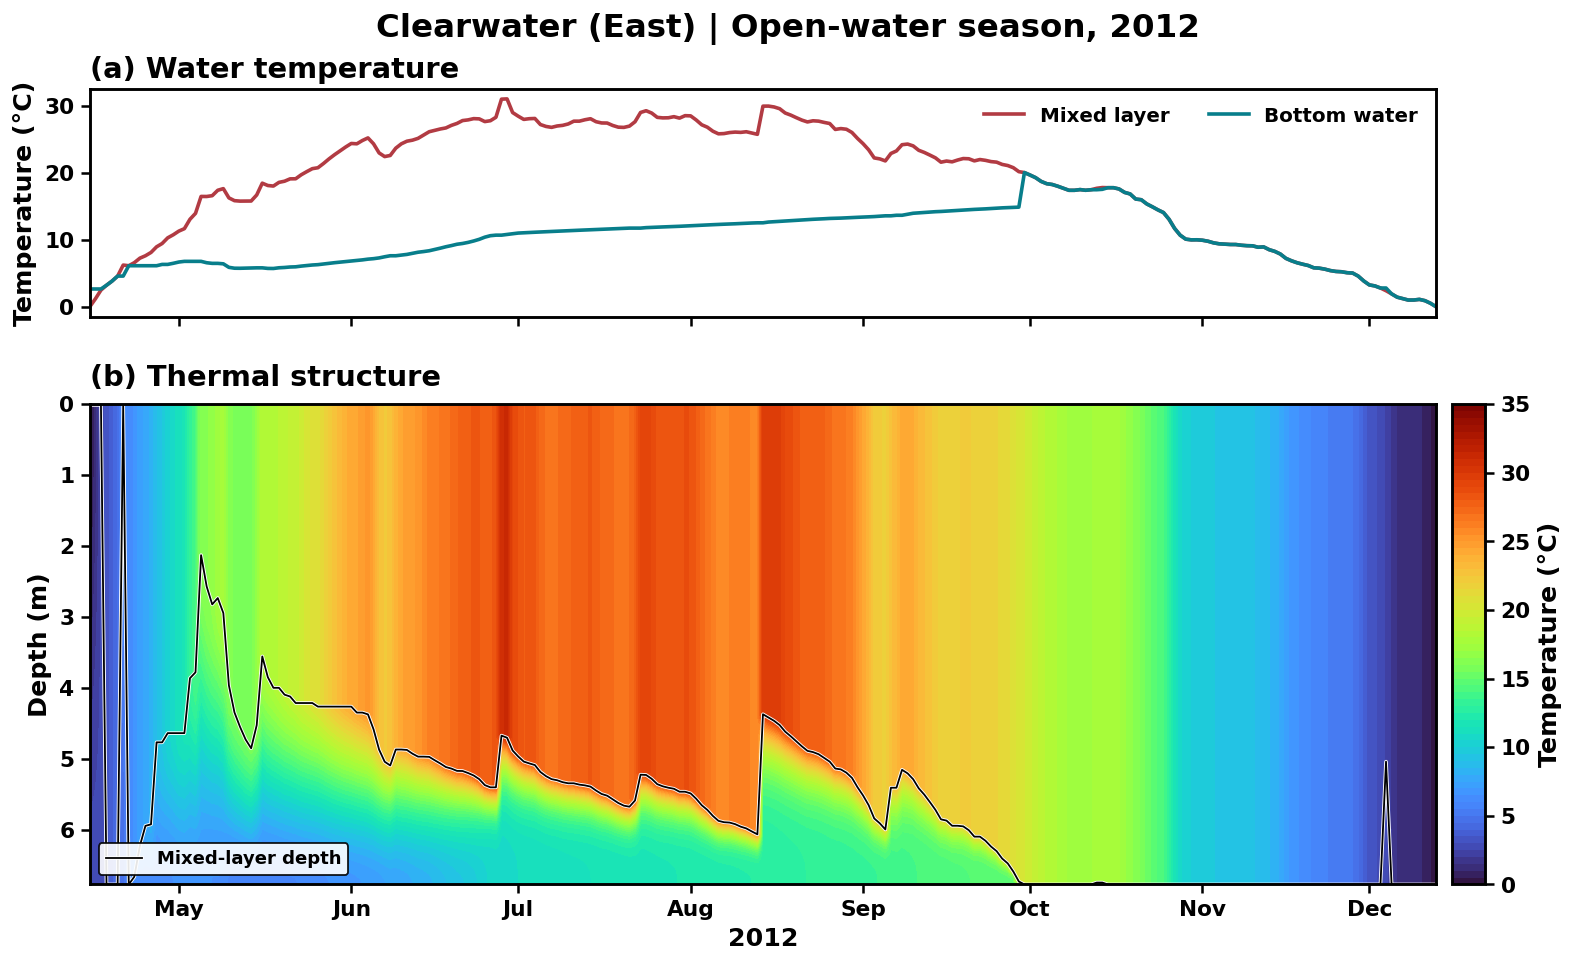

## 1. Load the model and example data

Run the next cell once. It loads the Python code and downloads the example data automatically. The first download is about **96 MiB**; later cells use the same data in this session.

No local Python installation is needed in Colab. The same notebook also runs in Jupyter from an extracted copy of this repository. For an existing local `FLake_Tutorial.zip`, set `LOCAL_DATA_ARCHIVE` to its path in the setup cell.


In [ ]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import tempfile

# Normally leave these unchanged. A local original ZIP is optional for offline use.
GITHUB_REPOSITORY = "Sandesh710/flake-python"
GITHUB_BRANCH = "main"
LOCAL_DATA_ARCHIVE = None

packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "IPython": "ipython", "ipywidgets": "ipywidgets"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def find_tutorial(folder):
    return next((p for p in [folder, folder / "flake-python", folder / "FLake_Tutorial"]
                 if (p / "flake/data_access.py").is_file()
                 and (p / "example_data.json").is_file()), None)

ROOT = find_tutorial(Path.cwd())
if ROOT is None:
    if not IN_COLAB:
        raise FileNotFoundError("Open this notebook inside the extracted flake-python repository.")
    destination = Path(tempfile.mkdtemp(prefix="flake_python_")) / "repository"
    subprocess.check_call([
        "git", "clone", "--quiet", "--depth", "1", "--branch", GITHUB_BRANCH,
        f"https://github.com/{GITHUB_REPOSITORY}.git", str(destination),
    ])
    ROOT = destination

ROOT = ROOT.resolve()
existing_flake = sys.modules.get("flake")
if existing_flake is not None and Path(existing_flake.__file__).resolve().parents[1] != ROOT:
    for name in list(sys.modules):
        if name == "flake" or name.startswith("flake."):
            sys.modules.pop(name)
sys.path.insert(0, str(ROOT))
from flake.data_access import ensure_example_data
ensure_example_data(ROOT, archive_path=LOCAL_DATA_ARCHIVE)

if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from flake import Lake, ModelOptions, InitialConditions, example_lakes, load_example, simulate
from flake.inputs import SCENARIO_LABELS, example_settings
from flake.observations import load_observations, observation_summary, observed_profile_figure
import ipywidgets as widgets
from flake.notebook import select_lake, ModelControls
from flake.plotting import thermal_figure, winter_figure, compare_temperature, compare_winter, forcing_plot
from flake.diagnostics import ice_dates, export_results

catalogue = example_lakes(ROOT)
print(f"Ready: {len(catalogue)} example lakes, 1995–2040 (historical + four SSPs).")


## 2. Select a lake

Select a lake from the menu. The map highlights its location and the table gives its mean depth, surface area and fetch. Mean depth sets the total depth of the FLake water column. Fetch characterizes the distance over which wind acts on the lake surface.

Choose **Historical** for 1995–2014, or an **SSP scenario** for a continuous 1995–2040 run. The historical segment is shared through 2014; scenario forcing starts on 1 January 2015. If you change either menu, rerun Section 3 onward.

In [ ]:
lake_menu = select_lake(catalogue, ROOT)
scenario_menu = widgets.Dropdown(
    options=[(label, key) for key, label in SCENARIO_LABELS.items()],
    value="historical", description="Forcing:",
    layout=widgets.Layout(width="95%"), style={"description_width": "80px"},
)
display(scenario_menu)

## 3. Prepare the meteorological inputs

FLake needs the atmospheric conditions at the lake surface. The example table contains one row per day, using the variables below. Water-column light extinction describes how quickly solar radiation is attenuated with depth.

| Column | Input | Unit |
|---|---|---|
| `date` | Daily date | YYYY-MM-DD |
| `air_temperature_c` | Air temperature | °C |
| `wind_speed_m_s` | Wind speed | m s⁻¹ |
| `vapor_pressure_mb` | Vapor pressure | mb (hPa) |
| `shortwave_w_m2` | Incoming shortwave radiation | W m⁻² |
| `longwave_w_m2` | Incoming longwave radiation | W m⁻² |
| `snowfall_kg_m2_s` | Snowfall water-equivalent mass flux | kg m⁻² s⁻¹ |
| `light_extinction_m_inv` | Water-column light extinction | m⁻¹ |

This implementation accepts daily forcing with a one-day timestep. Wind is supplied at 10 m, temperature and humidity at 2 m, and air pressure is set to 100,000 Pa by default. These settings can be specified through `ModelOptions` when preparing other datasets.

The example climate-model calendar omits February 29. Keep that calendar when using these inputs. For your own data, complete daily Gregorian records are also accepted. Missing forcing values and other date gaps must be resolved before running the model.

In [ ]:
scenario = scenario_menu.value
lake, meteo, historical_state = load_example(lake_menu.value, ROOT, scenario=scenario)
print(f"{lake.name} | GFDL-ESM4 | {SCENARIO_LABELS[scenario]}")
print(f"{meteo.date.min():%Y-%m-%d} to {meteo.date.max():%Y-%m-%d}")
display(meteo.head())

show_meteorology = False
if show_meteorology:
    meteorology_figure = forcing_plot(meteo, lake, year=2012)
    display(meteorology_figure)
    plt.close(meteorology_figure)

## 4. Choose lake properties, model components and initial conditions

### Lake properties

Use the example lake’s depth and fetch, or change them to explore their effects. The supplied light extinction can be retained or replaced with a constant value. A snow-retention factor represents reduced snow accumulation and its effect on modeled snow depth; the example lakes already have their assigned values.

### Model components

**Water column.** FLake predicts mixed-layer temperature and depth, bottom-water temperature and the evolving thermocline shape. Atmospheric heat exchange, solar absorption, wind mixing and convection determine the thermal response.

**Snow and ice.** The ice model simulates freezing, growth and melting. Enabling snow cover adds snow accumulation and insulation over lake ice. Disabling snow represents a bare-ice experiment; ice formation remains active.

**Sediments.** Enabling sediment heat exchange lets the lake store and release heat through its bottom boundary. Disabling it sets the bottom heat flux to zero. The example uses a 5 m sediment outer-boundary depth and a 6 °C lower-boundary temperature.

Snow and ice albedo endpoints are 0.60/0.10, with minimum snow thermal conductivity of 0.30 W m⁻¹ K⁻¹. These parameters are available through `ModelOptions`; there is no need to edit the physics code.

### Initial conditions

The historical simulations began in **1950** with a **fully mixed water column at approximately 4 °C**, **no ice or snow**, and sediment conditions set to **5 m and 6 °C**. The historical example here continues from the resulting lake state at the beginning of 1995.

To start a new experiment, choose **Specify initial conditions** and set water temperature and initial cover thickness. With no ice, the initial water column is fully mixed. With ice, the water surface is at freezing and the specified water temperature sets the bottom value. Changes to depth or model components automatically select this new-initialization mode. Early results then reflect those chosen initial conditions.

In [ ]:
settings = ModelControls(lake, historical_state, start_date=meteo.date.min()).display()

## 5. Run FLake

The controls define the lake, model options and starting state. `simulate` advances the model through the meteorological record and returns the simulated daily data. Changing a control takes effect when this cell is run again.

In [ ]:
configured_lake, options, initial_conditions, restart = settings.values()
result = simulate(
    configured_lake,
    meteo,
    options=options,
    initial_conditions=initial_conditions,
    restart=restart,
)
print(f"Completed {result.lake.name}: {len(result.daily):,} days.")
print("Initialization:", result.initialization)
display(result.daily[["date", "mixed_layer_temperature_c", "bottom_temperature_c",
                      "mixed_layer_depth_m", "ice_thickness_m", "snow_thickness_m"]].head())
# Clear any figures from a previous comparison when starting a new run.
comparison_thermal = None
comparison_cover = None
print("Forcing:", SCENARIO_LABELS[scenario])

## 6. Examine thermal structure

Select one year. The upper panel compares mixed-layer and bottom-water temperatures through the main open-water season. The lower panel shows temperature with depth, with the simulated mixed-layer depth overlaid.

The vertical temperature field is reconstructed from FLake’s layer temperatures, mixed-layer depth and thermocline shape factor. It represents the model’s assumed vertical structure, rather than independently simulated temperatures at each plotted depth. The deepest plotted level is the lake’s modeled mean depth.

The open-water view uses the longest continuous ice-free interval within the selected year. Full-year view also shows the under-ice field, with ice periods marked along the top edge. A 1 cm thickness threshold defines ice cover. In a cold ice-covered column, the profile reconstruction uses FLake’s linear conductive-temperature convention where applicable.

In [ ]:
available_years = sorted(pd.to_datetime(result.daily.date).dt.year.unique())
default_year = 2012 if scenario == "historical" else 2030
year_menu = widgets.Dropdown(options=[int(y) for y in available_years], value=default_year, description="Year:")
thermal_view = widgets.Dropdown(options=[("Open-water season", "open_water"), ("Full year; ice marked", "full_year")],
                                value="open_water", description="View:", layout=widgets.Layout(width="340px"))
display(widgets.HBox([year_menu, thermal_view]))

In [ ]:
display_year = int(year_menu.value)
thermal_plot = thermal_figure(result, year=display_year, view=thermal_view.value)
display(thermal_plot)
plt.close(thermal_plot)

## 7. Examine a winter’s snow and ice

Snow is shown above the snow–ice interface, and ice thickness increases downward below it. Both thickness axes are in centimeters.

Choose a complete winter by its ending year. Historical examples have complete winters ending in **1996–2014**; scenario examples extend through **2040**. For example, 2014 means the winter spanning 2013–2014. The plotted axis starts about ten days before cover forms and ends about ten days after the last cover; paired figures share the same date limits. Partial boundary winters are excluded.

In [ ]:
winter_years = list(range(int(result.daily.date.dt.year.min())+1, int(result.daily.date.dt.year.max())+1))
winter_menu = widgets.Dropdown(options=winter_years, value=2014 if scenario == "historical" else 2030,
                              description="Winter ending:", style={"description_width": "110px"})
display(winter_menu)

In [ ]:
winter_ending = int(winter_menu.value)
winter_plot = winter_figure(result, ending_year=winter_ending)
display(winter_plot)
plt.close(winter_plot)
display(ice_dates(result))

## 8. Compare two lakes

Select another lake and run the comparison cells. Temperature–depth sections use the same temperature color scale and date limits. If one lake freezes earlier, its temperature field is retained and ice cover is marked rather than leaving that panel blank. Snow/ice panels use common thickness scales so the cover can be compared directly.

When using the historical example, each lake begins from its own saved state. In experiment mode, the second lake uses the same model options and initial-condition settings as the first, while retaining its own depth, fetch and forcing. Differences between example lakes reflect both meteorological conditions and lake properties.

In [ ]:
import ipywidgets as widgets
second_lake_menu = widgets.Dropdown(
    options=[(f"{r.name} — {r.mean_depth_m:.1f} m", r.lake_id)
             for r in catalogue.sort_values("name").itertuples()],
    value="18044100", description="Second lake:",
    style={"description_width": "100px"}, layout=widgets.Layout(width="90%"),
)
display(second_lake_menu)

In [ ]:
second_lake, second_meteo, second_state = load_example(second_lake_menu.value, ROOT, scenario=scenario)
if second_lake.lake_id == lake.lake_id:
    raise ValueError("Choose a different second lake.")
second_result = simulate(
    second_lake,
    second_meteo,
    options=options,
    initial_conditions=initial_conditions,
    restart=second_state if restart is not None else None,
)
comparison_thermal = compare_temperature(result, second_result, year=display_year, view=thermal_view.value)
display(comparison_thermal)
plt.close(comparison_thermal)

In [ ]:
comparison_cover = compare_winter(result, second_result, ending_year=winter_ending)
display(comparison_cover)
plt.close(comparison_cover)

## 9. Download results

The download contains daily model output, seasonal ice dates, model settings and the displayed figures in PNG and PDF formats. CSV thicknesses are in meters; the snow/ice figures use centimeters.

In [ ]:
figures = {"thermal_structure": thermal_plot, "winter_snow_ice": winter_plot}
if globals().get("comparison_thermal") is not None:
    figures["two_lake_thermal_structure"] = comparison_thermal
if globals().get("comparison_cover") is not None:
    figures["two_lake_snow_ice"] = comparison_cover
archive = export_results(result, figures)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    display(FileLink(str(archive)))

## 10. Examine available observations

The included records contain historical temperature profiles and observed ice dates for the selected lakes. Availability differs by lake and year; three observation-cohort lakes have ice-off but no ice-on records in these source tables. The five supplementary lakes broaden the lake-property range and may lack thermal observations.

**These measurements are independent of the GFDL-ESM4 daily realization.** They provide observational context and should not be interpreted as a daily weather-matched validation. This section therefore displays the observations separately.


In [ ]:
observed_profiles, observed_ice = load_observations(lake.lake_id, ROOT)
display(observation_summary(observed_profiles, observed_ice))
if not observed_ice.empty:
    display(observed_ice[["winter_year", "ice_on_date", "ice_off_date"]].tail(8))
profile_dates = sorted(observed_profiles.date.dropna().dt.strftime("%Y-%m-%d").unique())
observed_date_menu = widgets.Dropdown(options=[("Do not plot a profile", None)] + [(d, d) for d in profile_dates],
                                    value=None, description="Profile date:", style={"description_width": "95px"})
display(observed_date_menu)

In [ ]:
if observed_date_menu.value is not None:
    observation_plot = observed_profile_figure(observed_profiles, observed_date_menu.value, lake.name)
    display(observation_plot)
    plt.close(observation_plot)

## 11. Use your own meteorological data

Prepare a CSV with the column names and units listed in Section 3. Supply incoming longwave radiation directly. Snowfall must be expressed as water-equivalent mass per area per second; one millimeter of daily snowfall water equivalent is one kilogram per square meter per day, so divide daily water-equivalent values by 86,400.

If the source provides precipitation rather than snowfall, partition it before running FLake. For the example preparation, precipitation is treated as all snow at air temperatures at or below 0 °C, decreasing linearly to no snow at 2 °C. Do not repeat that partitioning on data already supplied as snowfall.

The cell below provides a complete starting point. Set `use_own_data = True` to upload your CSV in Colab, or provide its path in Jupyter. Replace the illustrative lake properties with values for your lake. A snow-retention value of 1.0 uses full retention; a regional relationship requires independent justification for the new location.

In [ ]:
use_own_data = False
if use_own_data:
    if IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        names = [name for name in uploaded if name.lower().endswith(".csv")]
        if len(names) != 1:
            raise ValueError("Upload one meteorological CSV.")
        meteorology_path = names[0]
    else:
        meteorology_path = "my_meteorology.csv"

    my_meteo = pd.read_csv(meteorology_path, parse_dates=["date"])
    my_lake = Lake(
        name="My lake", mean_depth_m=8.0, fetch_m=2000.0,
        latitude=46.0, longitude=-93.0, area_km2=1.0,
        snow_retention=1.0,
    )
    my_options = ModelOptions(
        sediments=True, snow=True, light_extinction_m_inv=0.8,
        sediment_depth_m=5.0, sediment_temperature_c=6.0,
    )
    my_result = simulate(
        my_lake, my_meteo, options=my_options,
        initial_conditions=InitialConditions(water_temperature_c=4.0),
    )
    print(f"Completed {len(my_result.daily):,} days for {my_result.lake.name}.")

## Code guide and references

The code is organized by purpose:

| Module | Purpose |
|---|---|
| `configuration.py` | Lake properties, model options and initial conditions |
| `inputs.py` | Example loading and meteorological-input checks |
| `model.py` | Daily model integration |
| `physics.py` | FLake surface exchange, radiation, mixing, snow/ice and sediment physics |
| `profiles.py` | Vertical-temperature reconstruction |
| `plotting.py` | Thermal-structure and snow/ice figures |
| `diagnostics.py` | Ice dates and result downloads |
| `observations.py` | Available measured profiles and ice dates |
| `notebook.py` | Notebook selection and configuration controls |

These modules are in the `flake` folder. The notebook uses `simulate` for both the included examples and other daily datasets. See `docs/USER_GUIDE.md` for input preparation and additional options.

**Model reference**  
Mironov, D. V. (2008). *Parameterization of Lakes in Numerical Weather Prediction. Description of a Lake Model.* COSMO Technical Report No. 11. [doi:10.5676/DWD_pub/nwv/cosmo-tr_11](https://doi.org/10.5676/DWD_pub/nwv/cosmo-tr_11). The vertical-profile reconstruction follows Eq. (55).

**Companion application**  
Dahal, S., Ebtehaj, A., Olmanson, L., and Hondzo, M. *Projected Changes in Thermal Structure and Ice Phenology of Lakes in the Midwestern United States Over the Next Century.* Manuscript; citation details will be updated with the published version.

Original FLake ownership and attribution notices remain in the source and `NOTICE.md`. The example meteorology is derived from NEX-GDDP-CMIP6, with Minnesota lake properties and optical inputs from the companion study. The location map uses U.S. Census Bureau 2024 cartographic state boundaries.

FLake is a bulk model of a representative vertical column. Its temperature–depth sections do not resolve horizontal circulation or detailed bathymetry. Starting states and forcing quality affect the simulation; use an appropriate initialization or spin-up period for new applications.